# 05 · Regime filter (plan Step 07)

**The question:** given a 2σ signal today, will the spread revert?

**Label (pre-registered):** 1 if |z| ≤ 1 within 20 trading days, before first touching |z| = 4. The z-path uses the parameters frozen on the signal day.

**Model:** one logit pooled over the three traded spreads, with spread dummies. It is refit at each month start on episodes already resolved before that date, using the five core features fixed on 2026-10-24. With fewer than 20 resolved episodes there is no filter. A trade needs P ≥ 0.6, and an open trade exits if P < 0.4.

The logic is in `src/oilrv/regime.py` and `scripts/run_regime.py`. All results are a **spot proxy**.

In [1]:
import json
import pandas as pd
from IPython.display import Image
from oilrv.config import ROOT
import sys; sys.path.insert(0, str(ROOT / 'scripts'))
import run_regime
summary = run_regime.main()                  # about 10 s
T, F = ROOT / 'output/tables', ROOT / 'output/figures'
read = lambda n, **k: pd.read_csv(T / n, **k)
print('features:', summary['features'])
print('first month with a filter:', summary['first_month_with_filter'], '| months with a filter:', summary['months_with_filter'])

features: ['ovx_pct', 'garch_vol_pct', 'rolling_adf_p', 'gpr', 'inventory_dev_5y', 'd_brent_wti', 'd_ho_rb']
first month with a filter: 2014-09-02 | months with a filter: 146


## Episodes and base rates

In [2]:
read('05_episodes_summary.csv', index_col=0).round(3)

,episodes,share_reverted,share_gate_open,median_days,reverted,stopped,timed_out
key,,,,,,,
fixed|brent_wti,32,0.469,0.594,10.5,0.469,0.125,0.406
fixed|crack321,42,0.238,0.714,20.0,0.238,0.214,0.548
fixed|ho_rb,41,0.463,1.000,13.0,0.463,0.244,0.293
johansen|crack321,33,0.545,0.576,10.0,0.545,0.152,0.303


- **Few episodes.** There are 115 for the fixed spreads in 2010–26 (32–42 per spread). The plan warned about this, and it is why the logit is pooled.
- **Low base rates:** 24% of crack episodes, and about 47% of Brent–WTI and HO−RB episodes, reach |z| ≤ 1 within 20 days.
- **Why they are low:** the label asks z to fall from 2 to 1 in 20 days. With half-lives of 25–35 days (Part 4), that takes about one half-life on average, so most episodes run out of time (`timed_out`) rather than fail outright. With the 40-day label (pre-registered robustness, below), the base rate rises to 55%.

## Out-of-sample evaluation (point-in-time P on each signal day)

In [3]:
read('05_filter_eval.csv', index_col=0).round(3)

,episodes_total,episodes_with_p,success_all_oos,n_pass_filter,success_pass_filter,success_rejected,auc,brier_model,brier_base_rate
pooled (fixed),115.0,92.0,0.370,9.0,0.333,0.373,0.506,0.279,0.237
fixed|brent_wti,32.0,27.0,0.481,0.0,NaN,0.481,0.456,0.294,0.268
fixed|crack321,42.0,33.0,0.242,0.0,NaN,0.242,0.465,0.209,0.192
fixed|ho_rb,41.0,32.0,0.406,9.0,0.333,0.435,0.437,0.337,0.268
johansen|crack321,33.0,25.0,0.520,0.0,NaN,0.520,0.660,0.297,0.267
"pooled, gate open only",90.0,73.0,0.342,9.0,0.333,0.344,0.480,0.287,0.233


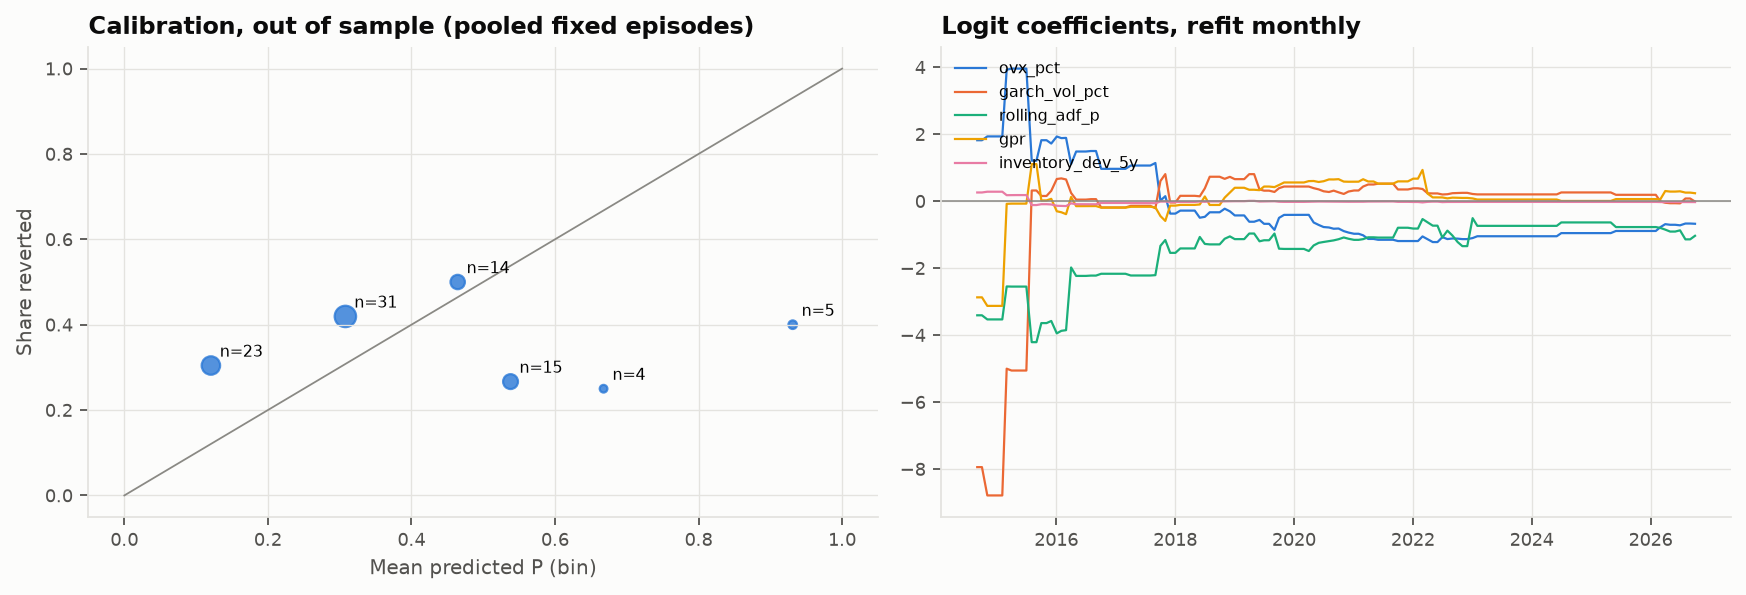

In [4]:
Image(str(F / '05_calibration_and_coefficients.png'))

In [5]:
read('05_calibration.csv', index_col=0).round(3)

,n,mean_p,share_reverted
p_hat,,,
"(-0.001, 0.2]",23,0.121,0.304
"(0.2, 0.4]",31,0.308,0.419
"(0.4, 0.5]",14,0.464,0.500
"(0.5, 0.6]",15,0.538,0.267
"(0.6, 0.7]",4,0.668,0.250
"(0.8, 1.0]",5,0.931,0.400


**The filter has no skill out of sample**
- **Discrimination:** pooled AUC is 0.51.
- **Accuracy:** its Brier score (0.279) is *worse* than a point-in-time base rate (0.237).
- **Calibration shows no relationship:** 25–50% of episodes revert in each probability bin, with no upward trend.
- **What passes:** only 9 of the 92 episodes with a P pass P ≥ 0.6, all of them HO−RB, and 3 of those 9 reverted.
- **Full-sample logit** (descriptive only, with look-ahead): no feature is significant.

**Why:** the 0.6 threshold sits well above the base rate of about 37%. So the filter works mostly as an *off switch*: it is rarely on, whatever the regime.

In [6]:
pd.read_csv(T / '05_logit_full_sample_descriptive.csv', index_col=0).round(3)

,coef,se,z,p
const,-1.659,1.975,-0.840,0.401
ovx_pct,-0.676,0.648,-1.042,0.297
garch_vol_pct,-0.013,0.709,-0.018,0.985
rolling_adf_p,-1.035,1.100,-0.940,0.347
gpr,0.237,0.381,0.623,0.533
inventory_dev_5y,-0.028,0.027,-1.036,0.300
d_brent_wti,0.856,0.569,1.504,0.133
d_ho_rb,0.923,0.538,1.715,0.086


## Point-in-time P(revert) through time

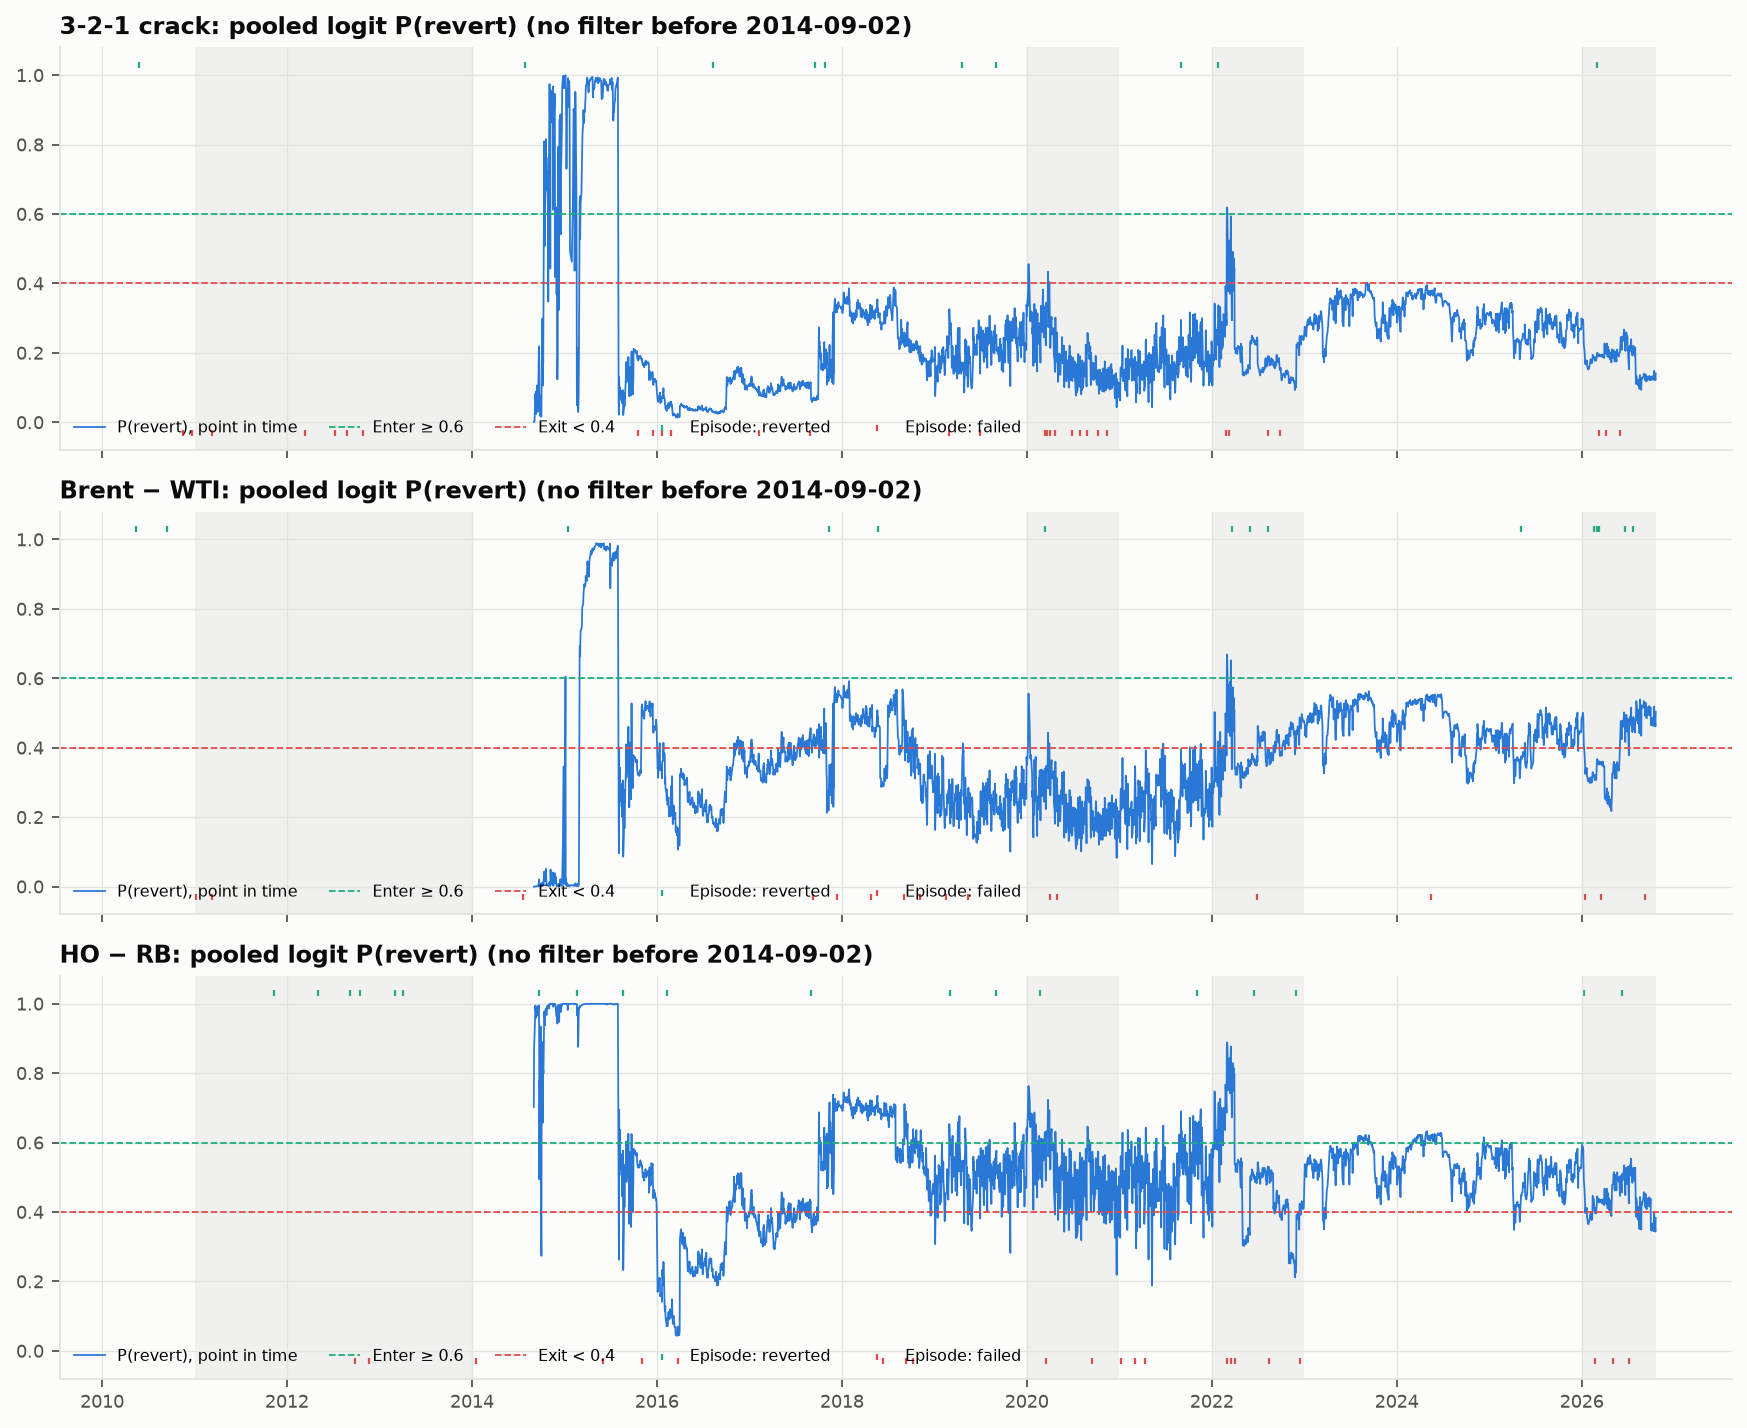

In [7]:
Image(str(F / '05_regime_probability.png'))

In [8]:
p = pd.read_csv(ROOT / 'data/derived/regime_probability.csv', index_col=[0, 1], parse_dates=['date'])
pd.DataFrame({k: {'days with P': int(p.loc[k, 'p_hat'].notna().sum()),
                  'share of days P >= 0.6': round(float((p.loc[k, 'p_hat'] >= 0.6).mean()), 3),
                  'median P': round(float(p.loc[k, 'p_hat'].median()), 3),
                  'P on last day': round(float(p.loc[k, 'p_hat'].iloc[-1]), 3)} for k in p.index.get_level_values(0).unique()}).T

,days with P,share of days P >= 0.6,median P,P on last day
fixed|crack321,2988.0,0.041,0.214,0.141
fixed|brent_wti,2988.0,0.027,0.369,0.504
fixed|ho_rb,2988.0,0.164,0.515,0.383
johansen|crack321,1794.0,0.001,0.264,0.312


- **2014–15:** the first fits swing between 0 and 1. That is near-separation: 8 parameters, 20–30 training episodes.
- **From 2016:**
  - The crack's P stays around 0.1–0.4.
  - Brent–WTI's stays around 0.2–0.55.
  - Only HO−RB regularly clears 0.6: in 2018 and 2020–21, and briefly in 2022.
- **Before September 2014** there is no filter at all, so in the backtest the filtered and unfiltered books are identical in 2010–14.

## The stress windows (G5 is judged in the backtest)

In [9]:
read('05_stress_windows.csv', index_col=[0, 1]).round(3)

episodes  success_all  with_p  passed  \
window          key                                                        
brent_wti_break fixed|brent_wti         2.0        0.000     0.0     0.0   
                fixed|crack321          5.0        0.000     0.0     0.0   
                fixed|ho_rb             8.0        0.750     0.0     0.0   
                johansen|crack321       5.0        0.400     0.0     0.0   
covid           fixed|brent_wti         3.0        0.333     3.0     0.0   
                fixed|crack321          9.0        0.000     9.0     0.0   
                fixed|ho_rb             3.0        0.333     3.0     0.0   
                johansen|crack321       2.0        0.000     2.0     0.0   
ukraine         fixed|brent_wti         4.0        0.750     4.0     0.0   
                fixed|crack321          5.0        0.200     5.0     0.0   
                fixed|ho_rb             7.0        0.286     7.0     2.0   
                johansen|crack321       7.0        0.857     7.0     0.0   
hormuz          fixed|brent_wti         8.0        0.625     8.0     0.0   
                fixed|crack321          4.0        0.250     4.0     0.0   
                fixed|ho_rb             5.0        0.400     5.0     0.0   
                johansen|crack321       6.0        0.667     6.0     0.0   

                                   blocked  success_passed  success_blocked  \
window          key                                                           
brent_wti_break fixed|brent_wti        0.0             NaN              NaN   
                fixed|crack321         0.0             NaN              NaN   
                fixed|ho_rb            0.0             NaN              NaN   
                johansen|crack321      0.0             NaN              NaN   
covid           fixed|brent_wti        3.0             NaN            0.333   
                fixed|crack321         9.0             NaN            0.000   
                fixed|ho_rb            3.0             NaN            0.333   
                johansen|crack321      2.0             NaN            0.000   
ukraine         fixed|brent_wti        4.0             NaN            0.750   
                fixed|crack321         5.0             NaN            0.200   
                fixed|ho_rb            5.0             0.0            0.400   
                johansen|crack321      7.0             NaN            0.857   
hormuz          fixed|brent_wti        8.0             NaN            0.625   
                fixed|crack321         4.0             NaN            0.250   
                fixed|ho_rb            5.0             NaN            0.400   
                johansen|crack321      6.0             NaN            0.667   

                                   mean_p  
window          key                        
brent_wti_break fixed|brent_wti       NaN  
                fixed|crack321        NaN  
                fixed|ho_rb           NaN  
                johansen|crack321     NaN  
covid           fixed|brent_wti     0.309  
                fixed|crack321      0.241  
                fixed|ho_rb         0.520  
                johansen|crack321   0.183  
ukraine         fixed|brent_wti     0.398  
                fixed|crack321      0.318  
                fixed|ho_rb         0.567  
                johansen|crack321   0.336  
hormuz          fixed|brent_wti     0.394  
                fixed|crack321      0.202  
                fixed|ho_rb         0.478  
                johansen|crack321   0.298

- **The filter blocks every crack and Brent–WTI episode in 2020, 2022 and 2026.**
  - In 2022, 2 HO−RB episodes passed, and both failed.
  - 2026 to date: all 17 fixed-spread episodes were blocked, and 8 of them (47%) would have reverted.
- So on the episode level, the filter does "keep the book out" of the stress years, as G5 asks. It does so because it keeps the book out most of the time, not because it tells good years from bad.
- **Risk for the gates:** with the filter on, the crack and Brent–WTI may not reach G2 (≥ 20 round trips). Part 6 will show this.

## Pre-registered robustness (reported, never gated)

In [10]:
read('05_robustness.csv', index_col=0).round(3)

,episodes_total,episodes_with_p,success_all_oos,n_pass_filter,success_pass_filter,success_rejected,auc,brier_model,brier_base_rate
probit,115.0,92.0,0.370,9.0,0.333,0.373,0.507,0.278,0.237
core + robustness features,115.0,35.0,0.429,5.0,0.400,0.433,0.467,0.304,0.250
label horizon 10d,134.0,90.0,0.222,0.0,NaN,0.222,0.539,0.188,0.175
label horizon 40d,106.0,83.0,0.554,32.0,0.531,0.569,0.481,0.312,0.252
logit core (gated config),115.0,92.0,0.370,9.0,0.333,0.373,0.506,0.279,0.237


- **Probit:** essentially identical to the logit.
- **Adding the robustness features** (CFTC managed-money z, hurricane season, event within 3 days) leaves only 35 usable episodes, because CFTC needs a long trailing window. AUC is 0.47.
- **The 40-day label** raises the base rate to 55% and lets 32 episodes pass, but AUC is still 0.48.
- **The conclusion holds across every variant:** these features do not predict reversion out of sample.

**Rules that stay fixed.** The core features, the 20-day label and the 0.6 threshold stay as registered. Changing any of them now would be exploratory (PREREGISTRATION.md §7).